# Anomaly detection from normal batches only (second solution, not scored)

**Objective.** Identify batches that deviate from normal behaviour, using only accepted batches for learning. No rejected batch and no label is used.

**Method.**
1. The hybrid model v7 predicts every labelled batch out-of-fold; the residual `log(measured / predicted)` describes the normal deviation of a batch from its forecast.
2. Each batch is compared with the residuals of the other 48 batches (leave-one-out).
3. Two kinds of detector are used: a batch-level score (D1, D2) and cell-level rules (spikes and persistent deviations).
4. No rejected batches exist, so detection performance is estimated with injected faults, and the false-alarm rate with the normal batches.
5. The 12 test batches have no measurements; only their inputs can be checked.

**Inputs.** `outputs/external_v7/` (copies of the v7 files of branch `hybrid_v3_tr`) and the event log in `data/`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXT, DATA, OUT = ROOT / "outputs" / "external_v7", ROOT / "data", ROOT / "outputs" / "ml"
OUT.mkdir(parents=True, exist_ok=True)
T = ["vcd", "tcd", "substrate", "byproduct"]
MEM = ["pf3a", "a3i_fp", "states", "tp"]          # the four members of hybrid v7

## 1. Residuals of the normal-behaviour model

The out-of-fold predictions of the four v7 members (7-fold cross-validation over whole batches, so no prediction has seen its own batch) are combined with the v7 blend weights (weighted geometric mean, one set per variable and day range). The finishing steps of v7 are not repeated. The residual of a batch is the vector of 52 values `log(measured / predicted)` (4 variables, 13 days).

In [2]:
m = pd.read_csv(EXT / "members_oof_v7c.csv", dtype={"batch_id": str})
W = pd.read_csv(EXT / "blend_weights.csv", index_col=[0, 1])
P = pd.DataFrame(index=m.index)
for v in T:
    out = np.zeros(len(m))
    for seg, days in (("days 1-6", range(1, 7)), ("days 7-13", range(7, 14))):
        w = W.loc[(v, seg), MEM].to_numpy(float)
        mk = m.day.isin(days).to_numpy()
        out[mk] = np.exp(np.column_stack([np.log(m.loc[mk, f"{s}|{v}"]) for s in MEM]) @ w)
    P[v] = out
P["tcd"] = np.maximum(P.tcd, P.vcd)

cv = {v: 100 * np.mean(np.abs(P[v] / m["obs_" + v] - 1)) for v in T}
print("MAPE of the blend (%):", {k: round(x, 2) for k, x in cv.items()}, "mean", round(np.mean(list(cv.values())), 2))

ids = list(dict.fromkeys(m.batch_id))
def to_matrix(values):
    df = pd.DataFrame({"batch_id": m.batch_id, "day": m.day, **values})
    return np.column_stack([df.pivot(index="batch_id", columns="day", values=v).loc[ids].to_numpy() for v in T])

Obs, Pred = np.log(to_matrix({v: m["obs_" + v] for v in T})), np.log(to_matrix({v: P[v] for v in T}))
R = Obs - Pred                                           # 49 batches x 52 residuals
RV = {v: R[:, 13 * j:13 * (j + 1)] for j, v in enumerate(T)}
print(f"typical spread of a residual (log units): {R.std(0).mean():.3f}")

MAPE of the blend (%): {'vcd': np.float64(6.72), 'tcd': np.float64(6.68), 'substrate': np.float64(7.19), 'byproduct': np.float64(8.04)} mean 7.16
typical spread of a residual (log units): 0.096


**Interpretation.** The blend reproduces the cross-validated error of v7 (7.16 %). The typical spread of a residual is 0.096 in log units, i.e. about 10 %. This spread is the normal deviation of a batch from its forecast and therefore sets the smallest deviation that can be detected.

## 2. Batch-level detectors

For each batch, the normal model is fitted on the other 48 batches. Two detectors are computed:

* **D1:** root mean square of the robust z-values (median and MAD of the other batches, each z clipped at 6) of the 52 residuals.
* **D2:** PCA of the normal residual patterns (3 components): **T²** measures the distance inside the components, **SPE** the distance outside them.

A batch is flagged if any of the three scores exceeds its 95 % quantile over the normal batches (5 % false alarms per score).

In [3]:
def fit_norm(Rm, k=3):
    mu = np.median(Rm, 0)
    sd = np.maximum(1.4826 * np.median(np.abs(Rm - mu), 0), 0.5 * Rm.std(0) + 1e-6)
    Z = (Rm - mu) / sd
    _, S, Vt = np.linalg.svd(Z - Z.mean(0), full_matrices=False)
    return dict(mu=mu, sd=sd, zm=Z.mean(0), V=Vt[:k], lam=(S[:k] ** 2) / (len(Rm) - 1))

def score(M, r):
    z = (r - M["mu"]) / M["sd"]
    zc = z - M["zm"]; t = zc @ M["V"].T
    return np.sqrt(np.mean(np.clip(z, -6, 6) ** 2, axis=1)), np.sum(t ** 2 / M["lam"], 1), np.sum((zc - t @ M["V"]) ** 2, 1)

S_batch = np.zeros((len(ids), 3))
for i in range(len(ids)):
    a = score(fit_norm(np.delete(R, i, 0)), R[i:i + 1]); S_batch[i] = [a[0][0], a[1][0], a[2][0]]
THR = np.quantile(S_batch, 0.95, axis=0)
flag = (S_batch > THR).any(axis=1)
print(f"thresholds: D1 {THR[0]:.2f}, T2 {THR[1]:.2f}, SPE {THR[2]:.1f}; flagged batches: {int(flag.sum())} of {len(ids)}")
display(pd.DataFrame(S_batch, index=ids, columns=["D1", "T2", "SPE"]).assign(flagged=flag)
        .sort_values("D1", ascending=False).head(6).round(2))

thresholds: D1 1.79, T2 6.69, SPE 128.3; flagged batches: 6 of 49


,D1,T2,SPE,flagged
Batch21,1.87,3.46,144.21,True
Batch47,1.86,1.29,176.13,True
Batch42,1.83,9.52,85.88,True
Batch59,1.73,8.09,56.65,True
Batch19,1.69,2.98,112.16,False
Batch4,1.64,3.69,95.70,False


**Interpretation.** Six of the 49 batches are flagged by at least one of the three scores. The scores of the highest-ranked batches lie close to the thresholds (D1 1.87 against 1.79), and the three scores flag different batches. No batch is a clear outlier at the level of the whole curve.

## 3. Cell-level rules

A batch score averages over 52 values, so a single extreme value is diluted. Two rules therefore test individual values. The z-value of a value is its distance, in robust standard deviations, from the residuals of the same variable and day in the other 48 batches.

| rule | definition | interpretation |
|---|---|---|
| spike | one value with absolute z of at least *s*, neighbouring days below *p* | probable measurement or sampling artefact |
| persistent deviation | absolute z of at least *p*, same sign, for at least 3 consecutive days (VCD, substrate, byproduct) | probable process difference |

Two levels are defined: **standard** (*s* = 5.5, *p* = 3.0) and **strict** (*s* = 6.5, *p* = 3.5). The thresholds were selected so that the standard level flags about 10 % of the normal batches, the level of the batch score. Looser thresholds flagged one quarter to one third of the batches.

In [4]:
def loo_z(Rv, i, row=None):
    others = np.delete(Rv, i, 0); mu = np.median(others, 0)
    sd = np.maximum(1.4826 * np.median(np.abs(others - mu), 0), 0.5 * others.std(0))
    return ((Rv[i] if row is None else row) - mu) / sd

LEVELS = {"strict": (6.5, 3.5, 3), "standard": (5.5, 3.0, 3)}      # (spike z, persistent z, persistent days)
PERS_VARS = ["vcd", "substrate", "byproduct"]

def find_deviations(z, spike, pers, ndays):
    """z: dict variable -> 13 z-values. Returns (type, variable, first day, last day, mean z) tuples."""
    found = []
    for v in T:
        for d in range(13):
            nb = [abs(z[v][k]) for k in (d - 1, d + 1) if 0 <= k < 13]
            if abs(z[v][d]) >= spike and max(nb) < pers:
                found.append(("spike", v, d + 1, d + 1, z[v][d]))
    for v in PERS_VARS:
        d = 0
        while d < 13:
            if abs(z[v][d]) >= pers:
                e = d
                while e + 1 < 13 and abs(z[v][e + 1]) >= pers and np.sign(z[v][e + 1]) == np.sign(z[v][d]):
                    e += 1
                if e - d + 1 >= ndays:
                    found.append(("persistent", v, d + 1, e + 1, float(np.mean(z[v][d:e + 1]))))
                d = e + 1
            else:
                d += 1
    return found

rows = []
for i, b in enumerate(ids):
    z = {v: loo_z(RV[v], i) for v in T}
    for typ, v, d0, d1, zv in find_deviations(z, *LEVELS["standard"]):
        strict = any(x[0] == typ and x[1] == v and x[2] <= d1 and x[3] >= d0 for x in find_deviations(z, *LEVELS["strict"]))
        rows.append({"batch": b, "type": typ, "variable": v, "days": str(d0) if d0 == d1 else f"{d0}-{d1}",
                     "mean z": round(zv, 1), "measured vs predicted (%)": round(100 * (np.exp(RV[v][i, d0 - 1:d1].mean()) - 1)),
                     "strict level": "yes" if strict else "no"})
dev = pd.DataFrame(rows)
display(dev.sort_values(["type", "mean z"], key=lambda s: s if s.dtype == object else -s.abs()).reset_index(drop=True))
print(f"standard level: {dev.batch.nunique()} of {len(ids)} batches flagged")

,batch,type,variable,days,mean z,measured vs predicted (%),strict level
0,Batch46,persistent,substrate,4-7,-5.7,-29,yes
1,Batch4,persistent,byproduct,2-6,-4.0,-22,no
2,Batch50,persistent,substrate,4-6,3.2,22,no
3,Batch34,spike,byproduct,13,7.6,270,yes
4,Batch29,spike,byproduct,13,7.1,242,yes


standard level: 5 of 49 batches flagged


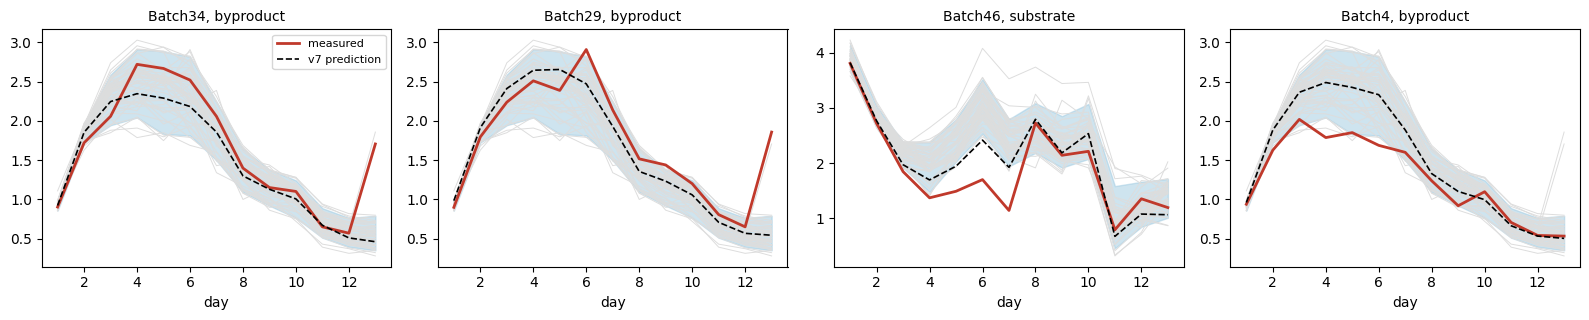

In [5]:
OBS = {v: np.exp(Obs[:, 13 * j:13 * (j + 1)]) for j, v in enumerate(T)}
PRD = {v: np.exp(Pred[:, 13 * j:13 * (j + 1)]) for j, v in enumerate(T)}
examples = [("Batch34", "byproduct"), ("Batch29", "byproduct"), ("Batch46", "substrate"), ("Batch4", "byproduct")]
days = np.arange(1, 14)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.3))
for ax, (b, v) in zip(axs, examples):
    for i in range(len(ids)):
        ax.plot(days, OBS[v][i], color="#dddddd", lw=0.7)
    ax.fill_between(days, np.percentile(OBS[v], 5, 0), np.percentile(OBS[v], 95, 0), color="#9ecae1", alpha=0.5)
    i = ids.index(b)
    ax.plot(days, OBS[v][i], color="#c0392b", lw=2, label="measured"); ax.plot(days, PRD[v][i], "k--", lw=1.2, label="v7 prediction")
    ax.set_title(f"{b}, {v}", fontsize=10); ax.set_xlabel("day")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "anomaly_v7_cell_level.png", dpi=130); plt.show()

**Interpretation.**

* The standard level flags 5 of 49 batches: two spikes (Batch34 and Batch29, byproduct on day 13, +270 % and +242 %) and three persistent deviations (Batch46 glucose -29 % on days 4-7, Batch4 lactate -22 % on days 2-6, Batch50 glucose +22 % on days 4-6). The strict level retains Batch34, Batch29 and Batch46.
* The two day-13 values rise from about 0.5 to 1.7-1.9 within one day, which is implausible for cell metabolism; a measurement or sampling problem is more likely.
* The flagged share (10 %) equals the false-alarm rate that the thresholds were set to give. The flagged batches are therefore candidates, not confirmed anomalies. The classification into artefacts and process differences is an interpretation to be confirmed by a process expert.

## 4. Evaluation with injected faults

No rejected batch is available. Faults are therefore injected into the residuals of normal batches, and the share of faulty batches that raise an alarm is measured. Every batch is judged against the normal model of the other 48 batches. The row *no fault* gives the false-alarm rate.

| fault | change applied | size (log change at the end) |
|---|---|---|
| growth stall | cells decrease, glucose increases, from day 4 | 0.1, 0.2, 0.3, 0.5 (about 10, 22, 35, 65 %) |
| lactate overproduction | byproduct increases, from day 3 | same |
| glucose feed failure | glucose decreases from day 8 | same |
| single assay outlier | one random value (variable, day) is shifted | same |

In [6]:
KINDS = ["growth stall", "lactate overproduction", "glucose feed failure", "single assay outlier"]
SEVS = [0.1, 0.2, 0.3, 0.5]

def fault(kind, sev, rng):
    f = np.zeros(52); ramp = lambda d0: np.clip((np.arange(1, 14) - d0) / (13 - d0), 0, 1)
    if kind == "growth stall":
        f[0:13] = -sev * ramp(4); f[13:26] = -sev * ramp(4); f[26:39] = 0.6 * sev * ramp(4)
    if kind == "lactate overproduction": f[39:52] = sev * ramp(3)
    if kind == "glucose feed failure": f[26:39] = -sev * (np.arange(1, 14) >= 8)
    if kind == "single assay outlier": f[rng.integers(0, 52)] = sev * rng.choice([-1, 1])
    return f

def alarms(i, f):
    a = score(fit_norm(np.delete(R, i, 0)), (R[i] + f)[None])
    batch = bool(a[0][0] > THR[0] or a[1][0] > THR[1] or a[2][0] > THR[2])
    z = {v: loo_z(RV[v], i, RV[v][i] + f[13 * j:13 * (j + 1)]) for j, v in enumerate(T)}
    return [batch, bool(find_deviations(z, *LEVELS["standard"])), bool(find_deviations(z, *LEVELS["strict"]))]

rng = np.random.default_rng(0)
COLS = ["batch score", "cell rules, standard", "cell rules, strict"]
res = {("no fault", ""): np.mean([alarms(i, np.zeros(52)) for i in range(len(ids))], axis=0)}
for kind in KINDS:
    for sev in SEVS:
        reps = 3 if kind == "single assay outlier" else 1
        res[(kind, sev)] = np.mean([alarms(i, fault(kind, sev, rng)) for _ in range(reps) for i in range(len(ids))], axis=0)
tab = pd.DataFrame(res, index=COLS).T
display(tab.round(2))

batch score  cell rules, standard  \
no fault                           0.12                  0.10   
growth stall           0.1         0.12                  0.14   
                       0.2         0.29                  0.27   
                       0.3         0.65                  0.47   
                       0.5         0.98                  0.94   
lactate overproduction 0.1         0.10                  0.10   
                       0.2         0.16                  0.12   
                       0.3         0.22                  0.18   
                       0.5         0.53                  0.65   
glucose feed failure   0.1         0.14                  0.18   
                       0.2         0.18                  0.31   
                       0.3         0.39                  0.78   
                       0.5         0.94                  0.98   
single assay outlier   0.1         0.13                  0.12   
                       0.2         0.14                  0.19   
                       0.3         0.17                  0.27   
                       0.5         0.39                  0.76   

                            cell rules, strict  
no fault                                  0.06  
growth stall           0.1                0.06  
                       0.2                0.10  
                       0.3                0.27  
                       0.5                0.84  
lactate overproduction 0.1                0.06  
                       0.2                0.06  
                       0.3                0.10  
                       0.5                0.39  
glucose feed failure   0.1                0.10  
                       0.2                0.16  
                       0.3                0.51  
                       0.5                0.98  
single assay outlier   0.1                0.07  
                       0.2                0.12  
                       0.3                0.16  
                       0.5                0.63

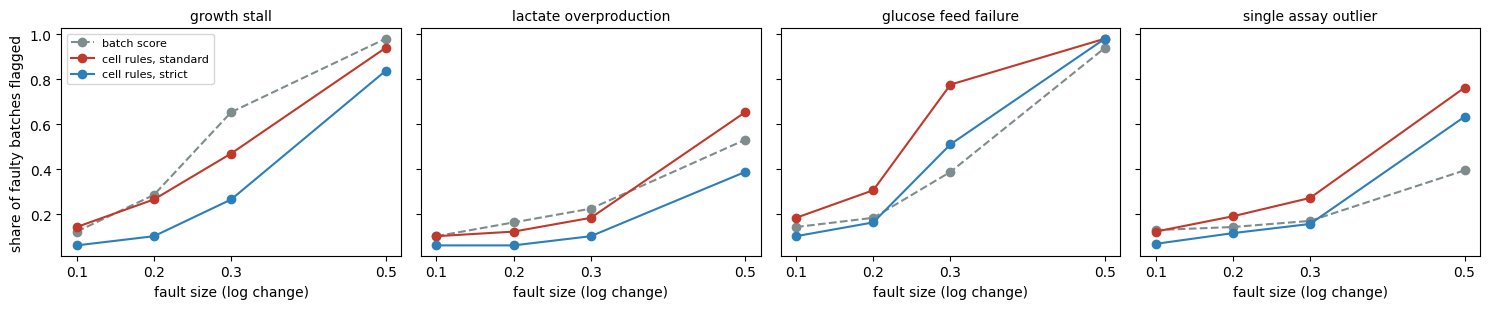

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
style = {"batch score": ("#7f8c8d", "--"), "cell rules, standard": ("#c0392b", "-"), "cell rules, strict": ("#2c7fb8", "-")}
for ax, kind in zip(axs, KINDS):
    for col, (colour, ls) in style.items():
        ax.plot(SEVS, [tab.loc[(kind, s), col] for s in SEVS], "o" + ls, color=colour, label=col)
    ax.set_title(kind, fontsize=10); ax.set_xticks(SEVS); ax.set_xlabel("fault size (log change)")
axs[0].set_ylabel("share of faulty batches flagged"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "anomaly_v7_detection.png", dpi=130); plt.show()

**Interpretation.**

* False-alarm rate on normal batches: 12 % (batch score), 10 % (cell rules, standard), 6 % (cell rules, strict).
* Faults of about 65 % (size 0.5) are detected in most cases: growth stall 98 / 94 / 84 %, glucose feed failure 94 / 98 / 98 %, single wrong value 39 / 76 / 63 %, lactate overproduction 53 / 65 / 39 % (batch score / standard / strict). Faults of 10-20 % are detected at about the false-alarm level and are therefore not distinguishable from normal variation.
* The detectors are complementary. The cell rules are better for local faults (glucose failure of size 0.3: 78 % against 39 %), the batch score for the diffuse growth stall (size 0.3: 65 % against 47 %).
* The faults are synthetic and of simple shape, and the cell-rule thresholds were selected on the same 49 batches, so the false-alarm rates are slightly optimistic.

## 5. Share of real alarms when bad batches are rare

The share of alarms that correspond to a real problem depends on the proportion of bad batches. With the false-alarm rate (FPR) and the average detection rate (TPR) of faults of size 0.5 from section 4:

`real alarms = 1000 · p · TPR`, `false alarms = 1000 · (1 − p) · FPR`, for *p* the proportion of bad batches.

In [8]:
rows = []
for col in COLS:
    tpr, fpr = np.mean([tab.loc[(k, 0.5), col] for k in KINDS]), tab.loc[("no fault", ""), col]
    for p in (0.001, 0.01, 0.05):
        real, false = 1000 * p * tpr, 1000 * (1 - p) * fpr
        rows.append({"detector": col, "bad batches": f"{p:.1%}", "detection": f"{tpr:.0%}", "false-alarm rate": f"{fpr:.0%}",
                     "alarms per 1000 batches": round(real + false), "real alarms": round(real, 1),
                     "share of alarms that are real": f"{real / (real + false):.0%}"})
display(pd.DataFrame(rows))

,detector,bad batches,detection,false-alarm rate,alarms per 1000 batches,real alarms,share of alarms that are real
0,batch score,0.1%,71%,12%,123,0.7,1%
1,batch score,1.0%,71%,12%,128,7.1,6%
2,batch score,5.0%,71%,12%,152,35.5,23%
3,"cell rules, standard",0.1%,83%,10%,103,0.8,1%
4,"cell rules, standard",1.0%,83%,10%,109,8.3,8%
5,"cell rules, standard",5.0%,83%,10%,139,41.7,30%
6,"cell rules, strict",0.1%,71%,6%,62,0.7,1%
7,"cell rules, strict",1.0%,71%,6%,68,7.1,10%
8,"cell rules, strict",5.0%,71%,6%,94,35.5,38%


**Interpretation.** If 0.1 % of the batches are bad, about 1 alarm in 100 is real for every detector. At 1 % the share is 6-10 %, at 5 % it is 23-38 %. The strict level gives the highest share of real alarms (10 % and 38 %) at the same detection as the batch score (71 %). The detector is therefore suitable as a screening tool when bad batches are not extremely rare; for a proportion of about 0.1 % the false-alarm rate would have to be reduced to 0.1-1 %, which would restrict detection to very large faults.

## 6. Input check of the 12 test batches

The residual-based checks need measurements, which are hidden for the test batches. Their inputs are available: day-0 values, feeds, volumes and the soft sensors derived from them (unlogged base volume, bolus size per culture volume, as in v3). Each test batch is compared with the 49 labelled batches by (i) the largest z-value of any feature, (ii) the training range of each feature, (iii) a PCA score (T², SPE; 4 components; thresholds at the 95 % quantile of the leave-one-out scores of the labelled batches).

In [9]:
ev = pd.read_csv(DATA / "bioreaction_remaining.csv", dtype={"batch_id": str})
tp = pd.read_csv(DATA / "bioreaction_template.csv", dtype={"batch_id": str})
test = list(dict.fromkeys(tp.batch_id)); allb = list(dict.fromkeys(ev.batch_id)); train = [b for b in allb if b not in test]
FEEDS = ["feed_substrate", "feed_b", "feed_c", "feed_d"]

Vol = {}                                                      # unlogged volume (adapted from hybrid_v3.volume_balance)
for bid, g in ev.groupby("batch_id"):
    g = g.sort_values("elapsed_time"); st = g[g.volume.notna()]; cum = g[FEEDS].fillna(0).sum(axis=1).cumsum()
    Vol[bid] = {int(round(s.elapsed_time)): s.volume - st.volume.iloc[0] - cum.loc[i] for i, s in st.iterrows()}
Vol = pd.DataFrame(Vol).T.sort_index(axis=1)
late = [k for k in Vol.columns if k >= 6]
sample = -np.polyfit(late, Vol[late].mean().to_numpy(), 1)[0]
A = Vol.add(sample * np.array(Vol.columns, dtype=float), axis=1); pre = A[[1, 2]].mean(axis=1)
base = pd.DataFrame({"base_to3": A[3] - pre, "base_to4": A[4] - pre, "base_to5": A[5] - pre, "base_tot": A[late].mean(axis=1) - pre})

rows = {}
for bid, g in ev.groupby("batch_id"):
    g = g.sort_values("elapsed_time"); st = g[g.volume.notna()]; fs = g[g.feed_substrate.notna()]; first = g[g.vcd.notna()].iloc[0]
    def per_volume(lo, hi):
        x = fs[(fs.elapsed_time > lo) & (fs.elapsed_time < hi)]
        return sum(r.feed_substrate / st[st.elapsed_time <= r.elapsed_time].volume.iloc[-1] for _, r in x.iterrows())
    rows[bid] = {"vcd0": first.vcd, "s0": first.substrate, "l0": first.byproduct, "v0": first.volume, "via0": first.vcd / first.tcd,
                 **{"tot_" + f: g[f].fillna(0).sum() for f in FEEDS}, "V_end": st.volume.iloc[-1],
                 "A_early": per_volume(6.0, 10.5), "A11": per_volume(10.5, 12.0), "A12": per_volume(12.0, 14.0)}
feat = pd.DataFrame(rows).T.astype(float).join(base).loc[allb]

Xtr = feat.loc[train]; Zf = (feat - Xtr.mean()) / Xtr.std().replace(0, 1); lo, hi = Xtr.min(), Xtr.max()
def fit_pca(X, k=4):
    m_, s_ = X.mean(), X.std().replace(0, 1)
    _, S, Vt = np.linalg.svd(((X - m_) / s_).to_numpy(), full_matrices=False)
    return m_, s_, Vt[:k], (S[:k] ** 2) / (len(X) - 1)
def pca_score(M, x):
    m_, s_, V, lam = M; z = ((x - m_) / s_).to_numpy(); t = z @ V.T
    return float(np.sum(t ** 2 / lam)), float(np.sum((z - t @ V) ** 2))
loo = np.array([pca_score(fit_pca(Xtr.drop(b)), Xtr.loc[b]) for b in train]); thr2 = np.quantile(loo, 0.95, axis=0); M_all = fit_pca(Xtr)

tab_in = []
for b in test:
    j = Zf.loc[b].abs().idxmax(); t2, spe = pca_score(M_all, feat.loc[b])
    outside = [col for col in feat.columns if feat.loc[b, col] < lo[col] - 1e-12 or feat.loc[b, col] > hi[col] + 1e-12]
    tab_in.append({"batch": b, "largest abs z": round(abs(Zf.loc[b, j]), 2), "feature": j, "outside training range": ", ".join(outside) or "-",
                   "T2": round(t2, 1), "SPE": round(spe, 1), "flag": "yes" if (t2 > thr2[0] or spe > thr2[1]) else ""})
display(pd.DataFrame(tab_in).sort_values("largest abs z", ascending=False).reset_index(drop=True))
print(f"thresholds: T2 {thr2[0]:.1f}, SPE {thr2[1]:.1f}")
print("largest abs z among the labelled batches (top 3):", Zf.loc[train].abs().max(1).sort_values(ascending=False).head(3).round(2).to_dict())

,batch,largest abs z,feature,outside training range,T2,SPE,flag
0,Batch54,3.78,s0,s0,5.6,20.5,yes
1,Batch57,2.89,l0,l0,2.9,17.4,
2,Batch5,2.50,l0,l0,7.8,2.4,yes
3,Batch40,2.50,l0,l0,3.6,5.5,
4,Batch32,2.46,vcd0,vcd0,4.1,9.2,
5,Batch35,2.43,A_early,"tot_feed_d, A11",4.2,10.5,
6,Batch6,2.42,A_early,-,1.2,11.9,
7,Batch48,2.32,base_to3,"base_to3, base_to4",3.7,4.2,
8,Batch24,2.24,A12,-,2.3,9.5,
9,Batch12,1.67,vcd0,-,1.8,3.1,


thresholds: T2 7.6, SPE 18.5
largest abs z among the labelled batches (top 3): {'Batch23': 3.78, 'Batch44': 3.36, 'Batch49': 2.61}


**Interpretation.** Batch54 is the most unusual test batch: its day-0 glucose is 3.8 standard deviations from the mean (the same z-value as the most extreme labelled batch, Batch23) and outside the training range, and its SPE (20.5) exceeds the threshold (18.5). Batch5 is flagged marginally (T2 7.8 against 7.6; day-0 lactate above the training range); day-0 lactate is also above the training range in Batch40 and Batch57. The remaining test batches lie within the training range for nearly all features. With 12 batches and 17 features a few values outside the range are expected by chance. The check concerns inputs only and gives no information about the outcome of a batch.

## 7. Conclusions and limitations

**Conclusions**

* A model of normal behaviour fitted on accepted batches only (v7 forecast and residual spread) supports two complementary checks: cell-level rules for local deviations and a batch score for diffuse ones. Large deviations (about 50 % and more) are detected reliably; deviations of 10-20 % are not.
* In the 49 training batches, two one-day spikes and three persistent deviations of glucose or lactate are identified. They are candidates for review, not confirmed anomalies.
* The detector is a screening tool: an alarm indicates that a person should examine the batch. Its practical value depends on the proportion of bad batches and the cost of a missed one (section 5).

**Limitations**

* No rejected batch is available; detection rates are based on injected faults.
* Thresholds are estimated on 49 batches and are noisy.
* The test batches can be checked on their inputs only. Each test batch contributes 1/12 of the leaderboard score, so one anomalous batch with an average error of 30 % would add about 2.5 points to the error of each variable concerned; such a batch cannot be predicted from day 0 and the log if its cause is not recorded there.
* The residual-based checks depend on out-of-fold v7 predictions; a deployed version would require regular re-fitting and day-by-day evaluation using only data available up to each day.